In [1]:
import pandas as pd
import requests

URL = "https://analisi.transparenciacatalunya.cat/resource/7bvh-jvq2.json"
params = {"$where": "codi_estacio='D5' AND codi_variable='1000'", "$limit": 5}
resp = requests.get(URL, params=params, timeout=30)
resp.raise_for_status()
df = pd.DataFrame(resp.json())
print(df.shape)
print(df.dtypes)
df.head()

(5, 9)
id               str
codi_estacio     str
nom_estacio      str
data_lectura     str
codi_variable    str
nom_variable     str
valor            str
unitat           str
estat            str
dtype: object


,id,codi_estacio,nom_estacio,data_lectura,codi_variable,nom_variable,valor,unitat,estat
0,D51000119504,D5,Barcelona - Observatori Fabra,1995-11-04T00:00:00.000,1000,Temperatura mitjana diària,13.7,°C,Representatiu
1,D51000119505,D5,Barcelona - Observatori Fabra,1995-11-05T00:00:00.000,1000,Temperatura mitjana diària,10.3,°C,Representatiu
2,D51000119506,D5,Barcelona - Observatori Fabra,1995-11-06T00:00:00.000,1000,Temperatura mitjana diària,11.5,°C,Representatiu
3,D51000119507,D5,Barcelona - Observatori Fabra,1995-11-07T00:00:00.000,1000,Temperatura mitjana diària,15.7,°C,Representatiu
4,D51000119508,D5,Barcelona - Observatori Fabra,1995-11-08T00:00:00.000,1000,Temperatura mitjana diària,16.4,°C,Representatiu


In [2]:
import xema

t = xema.download_daily("D5", "1000", "2019-01-01", "2025-12-31")
print(t.shape)
print(t["date"].min(), t["date"].max())
print(t["value"].isna().sum())
print(t["date"].diff().value_counts().head())
t.describe()

(2556, 2)
2019-01-01 00:00:00 2025-12-31 00:00:00
0
date
1 days    2554
2 days       1
Name: count, dtype: int64


,date,value
count,2556,2556.000000
mean,2022-07-01 23:27:19.436619,16.175743
min,2019-01-01 00:00:00,1.700000
25%,2020-09-30 18:00:00,11.000000
50%,2022-07-01 12:00:00,15.500000
75%,2024-04-01 06:00:00,21.425000
max,2025-12-31 00:00:00,33.400000
std,NaN,6.193858


In [3]:
full = pd.date_range("2019-01-01", "2025-12-31", freq="D")
missing = full.difference(t["date"])
print(missing)

DatetimeIndex(['2022-08-29'], dtype='datetime64[us]', freq='D')


In [4]:
import requests

B = "https://apidatos.ree.es/es/datos/demanda/evolucion"
p = {
    "start_date": "2022-01-01T00:00",
    "end_date": "2022-01-31T23:59",
    "time_trunc": "day",
    "geo_trunc": "electric_system",
    "geo_limit": "ccaa",
    "geo_ids": 9,
}
r = requests.get(B, params=p, timeout=60)
print(r.status_code)
print(r.text[:300])

400
{"errors":[{"status":"400","title":"Error Interno","detail":"Los datos solicitados no est\u00e1n disponibles en este momento. Int\u00e9ntelo de nuevo m\u00e1s tarde."}]}


(2557, 2) 0


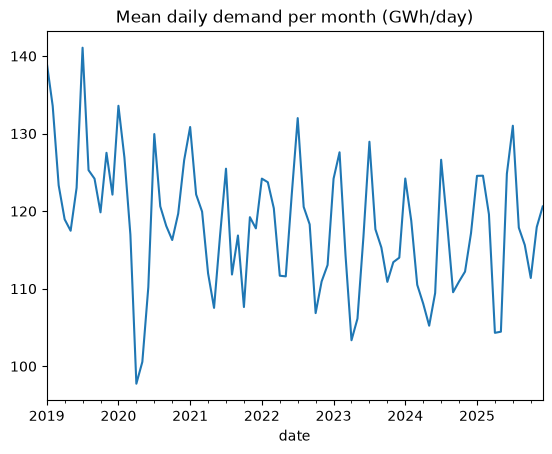

In [5]:
import xema

d = xema.download_demand("2019-01-01", "2025-12-31")
print(d.shape, d["demand_mwh"].isna().sum())

monthly = d.set_index("date")["demand_mwh"].resample("MS").mean() / 1000
monthly.plot(title="Mean daily demand per month (GWh/day)");

In [6]:
STATION = "X4"  # Barcelona - el Raval (urban, 33 m); D5 Fabra is in Collserola (410 m)
t = xema.download_daily(STATION, "1000", "2019-01-01", "2025-12-31")
t = t.rename(columns={"value": "temp_c"})
d = xema.download_demand("2019-01-01", "2025-12-31")

df = d.merge(t, on="date", how="inner", validate="one_to_one")
df["weekday"] = df["date"].dt.dayofweek
df["is_weekday"] = df["weekday"] < 5
print(df.shape)
print(df["is_weekday"].mean())

(2557, 5)
0.7145091904575674


In [7]:
import holidays

cat = holidays.Spain(subdiv="CT", years=range(2022, 2026))
for day, name in sorted(cat.items()):
    print(day, name)

2022-01-01 Año Nuevo
2022-01-06 Epifanía del Señor
2022-04-15 Viernes Santo
2022-04-18 Lunes de Pascua
2022-06-06 Día de la Pascua Granada
2022-06-24 San Juan
2022-08-15 Asunción de la Virgen
2022-10-12 Fiesta Nacional de España
2022-11-01 Todos los Santos
2022-12-06 Día de la Constitución Española
2022-12-08 Inmaculada Concepción
2022-12-26 San Esteban
2023-01-06 Epifanía del Señor
2023-04-07 Viernes Santo
2023-04-10 Lunes de Pascua
2023-05-01 Fiesta del Trabajo
2023-06-24 San Juan
2023-08-15 Asunción de la Virgen
2023-09-11 Fiesta Nacional de Cataluña
2023-10-12 Fiesta Nacional de España
2023-11-01 Todos los Santos
2023-12-06 Día de la Constitución Española
2023-12-08 Inmaculada Concepción
2023-12-25 Natividad del Señor
2023-12-26 San Esteban
2024-01-01 Año Nuevo
2024-01-06 Epifanía del Señor
2024-03-29 Viernes Santo
2024-04-01 Lunes de Pascua
2024-05-01 Fiesta del Trabajo
2024-06-24 San Juan
2024-08-15 Asunción de la Virgen
2024-09-11 Fiesta Nacional de Cataluña
2024-10-12 Fiesta Na

In [8]:
df["is_holiday"] = df["date"].dt.date.isin(cat.keys())
sel = df.loc[
    (df["date"] >= "2022-01-01")
    & df["is_weekday"]
    & ~df["is_holiday"]
].copy()
print(sel.shape)

(998, 6)


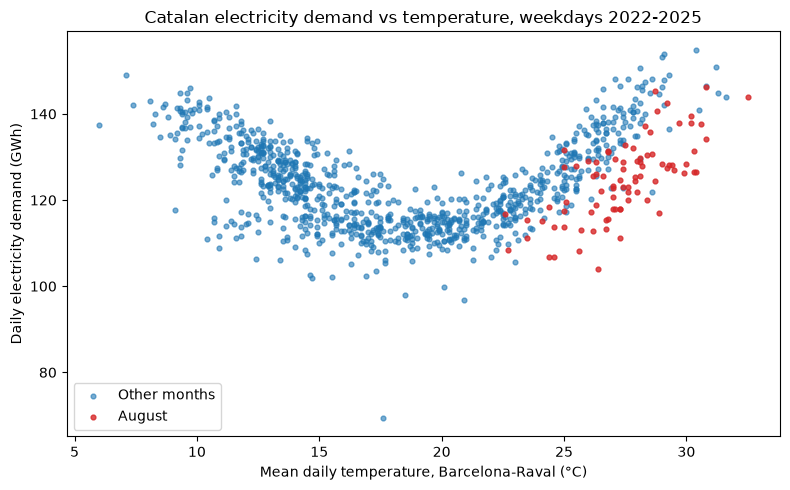

In [9]:
import matplotlib.pyplot as plt

sel = sel.assign(
    demand_gwh=sel["demand_mwh"] / 1000,
    is_august=sel["date"].dt.month == 8,
)

fig, ax = plt.subplots(figsize=(8, 5))
other = sel.loc[~sel["is_august"]]
aug = sel.loc[sel["is_august"]]
ax.scatter(other["temp_c"], other["demand_gwh"], s=12, alpha=0.6, label="Other months")
ax.scatter(aug["temp_c"], aug["demand_gwh"], s=12, alpha=0.8, color="tab:red", label="August")
ax.set_xlabel("Mean daily temperature, Barcelona-Raval (°C)")
ax.set_ylabel("Daily electricity demand (GWh)")
ax.set_title("Catalan electricity demand vs temperature, weekdays 2022-2025")
ax.legend()
fig.tight_layout()

In [10]:
import numpy as np

fit = sel.loc[~sel["is_august"] & (sel["date"] != "2025-04-28")]
t = fit["temp_c"].to_numpy()
y = fit["demand_gwh"].to_numpy()


def hinge_fit(t, y, t_cold, t_hot):
    X = np.column_stack([
        np.ones(len(t)),
        np.clip(t_cold - t, 0, None),
        np.clip(t - t_hot, 0, None),
    ])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    rss = ((y - X @ coef) ** 2).sum()
    return coef, rss


best = None
for t_cold in np.arange(10, 20.5, 0.5):
    for t_hot in np.arange(t_cold, 24.5, 0.5):
        coef, rss = hinge_fit(t, y, t_cold, t_hot)
        if best is None or rss < best[0]:
            best = (rss, t_cold, t_hot, coef)

print(len(fit), best[1], best[2], best[3])

912 17.0 22.0 [114.37699779   2.91061843   4.22932855]


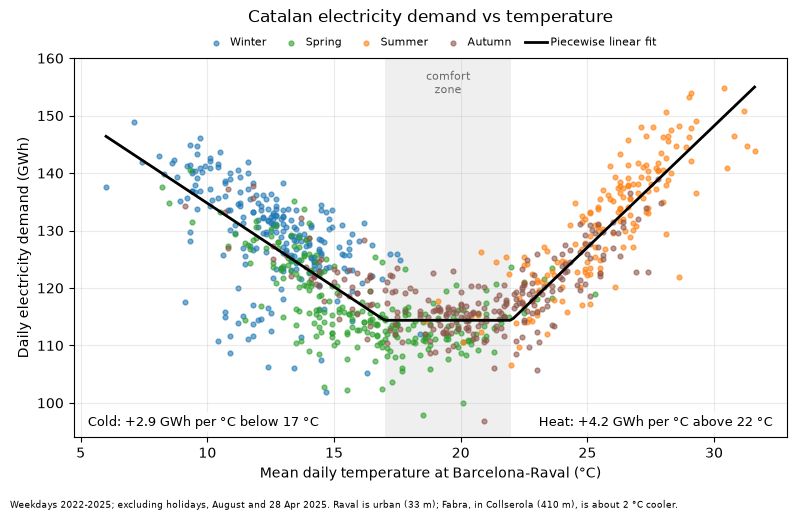

In [11]:
from pathlib import Path

base, s_cold, s_hot = best[3]
t_cold, t_hot = best[1], best[2]

season_names = ["Winter", "Spring", "Summer", "Autumn"]
season_colors = ["tab:blue", "tab:green", "tab:orange", "tab:brown"]
fit = fit.assign(season=fit["date"].dt.month % 12 // 3)

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.axvspan(t_cold, t_hot, color="grey", alpha=0.12, lw=0)
for k, (name, color) in enumerate(zip(season_names, season_colors)):
    d = fit.loc[fit["season"] == k]
    ax.scatter(d["temp_c"], d["demand_gwh"], s=12, alpha=0.6, color=color, label=name)

grid = np.linspace(fit["temp_c"].min(), fit["temp_c"].max(), 200)
curve = (base + s_cold * np.clip(t_cold - grid, 0, None)
         + s_hot * np.clip(grid - t_hot, 0, None))
ax.plot(grid, curve, color="black", lw=2, label="Piecewise linear fit")

box = dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2)
ax.text(0.02, 0.03, f"Cold: +{s_cold:.1f} GWh per °C below {t_cold:.0f} °C",
        transform=ax.transAxes, ha="left", fontsize=9, bbox=box)
ax.text(0.98, 0.03, f"Heat: +{s_hot:.1f} GWh per °C above {t_hot:.0f} °C",
        transform=ax.transAxes, ha="right", fontsize=9, bbox=box)
ax.text((t_cold + t_hot) / 2, 158, "comfort\nzone", fontsize=8, ha="center",
        va="top", color="dimgrey")

ax.set_ylim(94, 160)
ax.grid(alpha=0.25)
ax.set_xlabel("Mean daily temperature at Barcelona-Raval (°C)")
ax.set_ylabel("Daily electricity demand (GWh)")
ax.set_title("Catalan electricity demand vs temperature", pad=26)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5, fontsize=8,
          frameon=False, columnspacing=1.2, handletextpad=0.3)
fig.text(0.01, 0.012,
         "Weekdays 2022-2025; excluding holidays, August and 28 Apr 2025. "
         "Raval is urban (33 m); Fabra, in Collserola (410 m), is about 2 °C cooler.",
         fontsize=6.5, ha="left")
fig.tight_layout(rect=(0, 0.035, 1, 1))

out = Path("..") / "figures" / "Gabri"
out.mkdir(parents=True, exist_ok=True)
out.mkdir(exist_ok=True)
fig.savefig(out / "idea6_demand_vs_temperature.png", dpi=200)
fig.savefig(out / "idea6_demand_vs_temperature.svg")


In [12]:
# Same fit, same 912 days, with three Barcelona stations
# (station metadata comes from the XEMA stations dataset yqwd-vj5e)
import requests

meta = pd.DataFrame(requests.get(
    "https://analisi.transparenciacatalunya.cat/resource/yqwd-vj5e.json",
    params={"$where": "codi_estacio in('D5','X4','X8')"}, timeout=30,
).json()).set_index("codi_estacio")
meta = meta.assign(altitude_m=pd.to_numeric(meta["altitud"]))
area = {
    "X4": "Ciutat Vella: dense old town, urban",
    "X8": "Les Corts: UB campus, mid-city",
    "D5": "Collserola hills: forest, above the city",
}

dem = xema.download_demand("2019-01-01", "2025-12-31")
rows = []
for st in ["X4", "X8", "D5"]:
    ts = xema.download_daily(st, "1000", "2019-01-01", "2025-12-31")
    ts = ts.rename(columns={"value": "temp_c"})
    s = dem.merge(ts, on="date").loc[lambda x: x["date"].isin(fit["date"])]
    t = s["temp_c"].to_numpy()
    y = s["demand_mwh"].to_numpy() / 1000
    best_st = None
    for tc in np.arange(10, 20.5, 0.5):
        for th in np.arange(tc, 24.5, 0.5):
            coef, rss = hinge_fit(t, y, tc, th)
            if best_st is None or rss < best_st[0]:
                best_st = (rss, tc, th, coef)
    rows.append({
        "station": st, "n": len(s), "t_cold": best_st[1], "t_hot": best_st[2],
        "slope_cold": round(best_st[3][1], 2), "slope_hot": round(best_st[3][2], 2),
        "rmse_gwh": round((best_st[0] / len(s)) ** 0.5, 2),
    })

res = pd.DataFrame(rows).set_index("station")
info = meta.loc[res.index, ["nom_estacio", "emplacament", "altitude_m", "latitud", "longitud"]]
info.insert(1, "area", pd.Series(area))
pd.concat([info, res], axis=1)


,nom_estacio,area,emplacament,altitude_m,latitud,longitud,n,t_cold,t_hot,slope_cold,slope_hot,rmse_gwh
station,,,,,,,,,,,,
X4,Barcelona - el Raval,"Ciutat Vella: dense old town, urban",Facultat de Geografia i Història. c. Montalegr...,33,41.38386,2.16774,912,17.0,22.0,2.91,4.23,5.80
X8,Barcelona - Zona Universitària,"Les Corts: UB campus, mid-city",Pistes UB,82,41.37922,2.10537,912,17.0,21.0,2.54,3.90,5.76
D5,Barcelona - Observatori Fabra,"Collserola hills: forest, above the city",Observatori Fabra,410,41.41864,2.12379,912,15.0,19.0,2.42,3.22,6.20


In [13]:
# Figure 2 data: monthly generation by technology and reservoir volume
gen = xema.download_generation(2019, 2025)
res = xema.download_reservoirs("2019-01-01", "2025-12-31")

# capacity of each reservoir = volume / (pct / 100); the median removes rounding noise
cap = (res["volume_hm3"] / (res["pct"] / 100)).groupby(res["reservoir"]).median()
res = res.assign(capacity_hm3=res["reservoir"].map(cap))

# basin-level percentage = total volume / total capacity (not the mean of percentages)
basin = res.groupby("date").agg(
    volume=("volume_hm3", "sum"), capacity=("capacity_hm3", "sum")
)
basin = basin.assign(pct=100 * basin["volume"] / basin["capacity"])
basin_m = basin["pct"].resample("MS").mean()

gen_p = gen.pivot(index="date", columns="technology", values="value_mwh") / 1000  # GWh
print(gen_p.shape, cap.sum().round(1))


(84, 11) 694.4


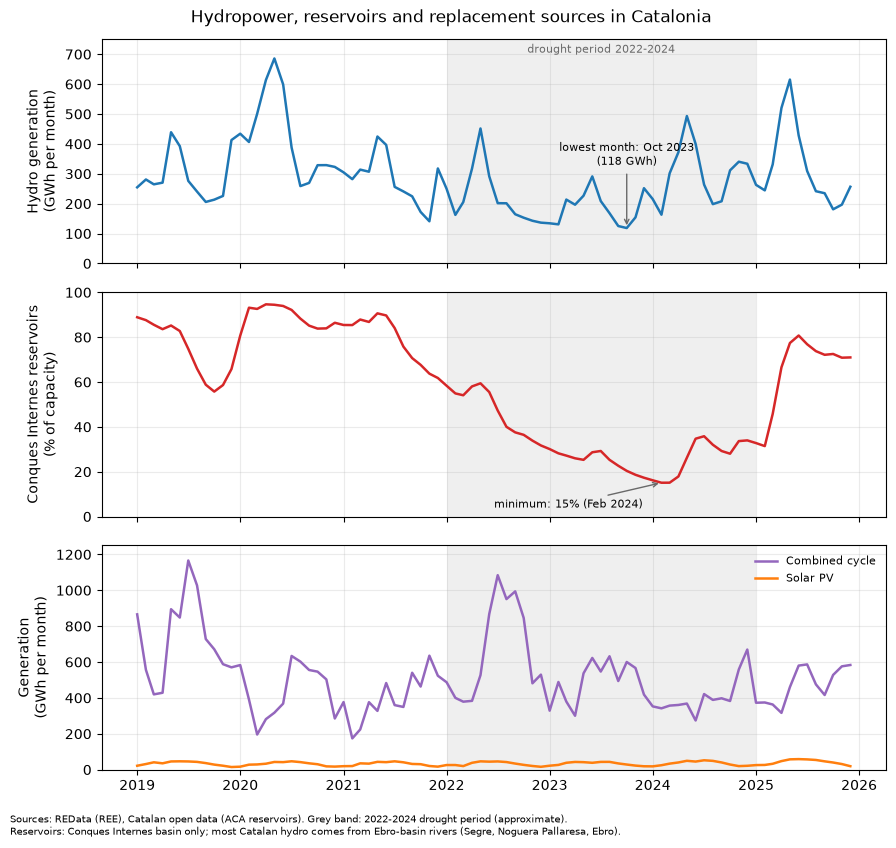

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(9, 8.5), sharex=True)
drought = (pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"))

axes[0].plot(gen_p.index, gen_p["Hidráulica"], color="tab:blue", lw=1.8)
axes[0].set_ylabel("Hydro generation\n(GWh per month)")
axes[0].set_ylim(0, 750)

axes[1].plot(basin_m.index, basin_m, color="tab:red", lw=1.8)
axes[1].set_ylabel("Conques Internes reservoirs\n(% of capacity)")
axes[1].set_ylim(0, 100)

# same y axis for both technologies, so their sizes can be compared directly
axes[2].plot(gen_p.index, gen_p["Ciclo combinado"], color="tab:purple", lw=1.8,
             label="Combined cycle")
axes[2].plot(gen_p.index, gen_p["Solar fotovoltaica"], color="tab:orange", lw=1.8,
             label="Solar PV")
axes[2].set_ylabel("Generation\n(GWh per month)")
axes[2].set_ylim(0, 1250)
axes[2].legend(frameon=False, fontsize=8, loc="upper right")

for ax in axes:
    ax.axvspan(*drought, color="grey", alpha=0.12, lw=0)
    ax.grid(alpha=0.25)

mid = drought[0] + (drought[1] - drought[0]) / 2
axes[0].text(mid, 735, "drought period 2022-2024", ha="center", va="top",
             fontsize=8, color="dimgrey")

h = gen_p["Hidráulica"]
axes[0].annotate(f"lowest month: {h.idxmin():%b %Y}\n({h.min():.0f} GWh)",
                 xy=(h.idxmin(), h.min()), xytext=(h.idxmin(), 330),
                 ha="center", fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="dimgrey"))
axes[1].annotate(f"minimum: {basin_m.min():.0f}% ({basin_m.idxmin():%b %Y})",
                 xy=(basin_m.idxmin(), basin_m.min()),
                 xytext=(basin_m.idxmin() - pd.Timedelta(days=330), 4),
                 ha="center", fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="dimgrey"))

fig.suptitle("Hydropower, reservoirs and replacement sources in Catalonia")
fig.text(0.01, 0.005,
         "Sources: REData (REE), Catalan open data (ACA reservoirs). Grey band: 2022-2024 "
         "drought period (approximate).\nReservoirs: Conques Internes basin only; most "
         "Catalan hydro comes from Ebro-basin rivers (Segre, Noguera Pallaresa, Ebro).",
         fontsize=7, ha="left", va="bottom")
fig.tight_layout(rect=(0, 0.04, 1, 1))

out = Path("..") / "figures" / "Gabri"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "idea6_hydro_vs_reservoirs.png", dpi=200)
fig.savefig(out / "idea6_hydro_vs_reservoirs.svg")


In [15]:
# Rain test: monthly precipitation in the Pyrenees (XEMA variable 1300, valley stations)
pyr = ["Y4", "W5", "CJ", "CD", "CT", "DP", "YA", "WQ", "CP", "XQ", "YC", "XH", "YG"]
rain = {}
for st in pyr:
    dd = xema.download_daily(st, "1300", "2019-01-01", "2025-12-31").set_index("date")["value"]
    mm = dd.resample("MS").agg(["sum", "count"])
    rain[st] = mm["sum"].where(mm["count"] >= 25)  # drop months with too few days
rain_m = pd.DataFrame(rain).mean(axis=1)  # mean monthly total over the stations (mm)
hydro = gen_p["Hidráulica"]


def anomaly(s):
    # value minus the mean of the same calendar month: removes the seasonal cycle
    return s - s.groupby(s.index.month).transform("mean")


h_an, r_an = anomaly(hydro), anomaly(rain_m)
xcorr = pd.Series({k: h_an.corr(r_an.shift(k)) for k in range(-3, 7)})  # k > 0: rain leads
r6 = r_an.rolling(6).sum().shift(1)  # rain anomaly accumulated over the previous 6 months
print("cross-correlation by lag:", xcorr.round(2).to_dict())
print("hydro anomaly vs previous 6-month rain anomaly:", round(h_an.corr(r6), 2))

annual = pd.DataFrame({"hydro_gwh": hydro.resample("YS").sum(),
                       "rain_mm": rain_m.resample("YS").sum()})
annual.index = annual.index.year
print(annual.round(0).T.to_string())
print("annual correlation:", round(annual.corr().iloc[0, 1], 2))


cross-correlation by lag: {-3: 0.3, -2: 0.14, -1: 0.1, 0: 0.34, 1: 0.49, 2: 0.42, 3: 0.25, 4: 0.2, 5: 0.24, 6: 0.36}
hydro anomaly vs previous 6-month rain anomaly: 0.72
date         2019    2020    2021    2022    2023    2024    2025
hydro_gwh  3477.0  5136.0  3382.0  2678.0  2220.0  3600.0  3823.0
rain_mm     654.0   747.0   566.0   546.0   459.0   763.0   775.0
annual correlation: 0.8


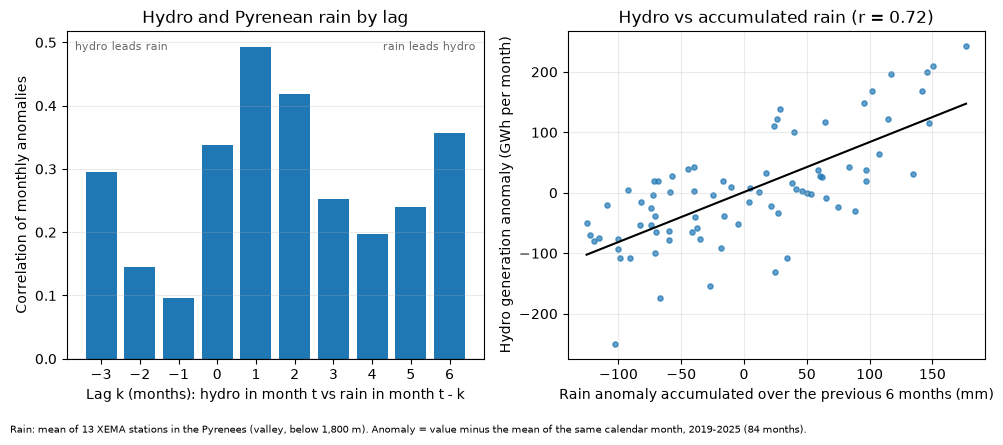

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.4))

ax1.bar(xcorr.index, xcorr.values, color="tab:blue")
ax1.axhline(0, color="black", lw=0.8)
ax1.set_xticks(list(xcorr.index))
ax1.set_xlabel("Lag k (months): hydro in month t vs rain in month t - k")
ax1.set_ylabel("Correlation of monthly anomalies")
ax1.set_title("Hydro and Pyrenean rain by lag")
ax1.text(0.02, 0.97, "hydro leads rain", transform=ax1.transAxes, va="top",
         fontsize=8, color="dimgrey")
ax1.text(0.98, 0.97, "rain leads hydro", transform=ax1.transAxes, va="top",
         ha="right", fontsize=8, color="dimgrey")
ax1.grid(alpha=0.25, axis="y")

ok = pd.concat([r6, h_an], axis=1, keys=["x", "y"]).dropna()
ax2.scatter(ok["x"], ok["y"], s=14, alpha=0.7, color="tab:blue")
slope, intercept = np.polyfit(ok["x"], ok["y"], 1)
xs = np.array([ok["x"].min(), ok["x"].max()])
ax2.plot(xs, intercept + slope * xs, color="black", lw=1.5)
ax2.set_xlabel("Rain anomaly accumulated over the previous 6 months (mm)")
ax2.set_ylabel("Hydro generation anomaly (GWh per month)")
ax2.set_title(f"Hydro vs accumulated rain (r = {ok['x'].corr(ok['y']):.2f})")
ax2.grid(alpha=0.25)

fig.text(0.01, 0.005,
         "Rain: mean of 13 XEMA stations in the Pyrenees (valley, below 1,800 m). Anomaly = "
         "value minus the mean of the same calendar month, 2019-2025 (84 months).",
         fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 1))

out = Path("..") / "figures" / "Gabri"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "idea6_hydro_vs_rain.png", dpi=200)
fig.savefig(out / "idea6_hydro_vs_rain.svg")


In [17]:
# Main figure 2: who covers the change in generation? Annual change by source (GWh)
ind = xema.download_indicators("2019-01-01", "2025-12-31")
imports_y = ind.set_index("date")["net_imports_gwh"].resample("YS").sum()

groups = {
    "Hydro": ["Hidráulica"],
    "Combined cycle": ["Ciclo combinado"],
    "Nuclear": ["Nuclear"],
    "Cogeneration": ["Cogeneración"],
    "Wind": ["Eólica"],
    "Solar PV": ["Solar fotovoltaica"],
    "Other": ["Solar térmica", "Otras renovables",
              "Residuos no renovables", "Residuos renovables"],
}
annual_src = pd.DataFrame(
    {name: gen_p[cols].sum(axis=1).resample("YS").sum() for name, cols in groups.items()}
)
annual_src["Net imports"] = imports_y
change = annual_src.diff().dropna()  # change versus the previous year (GWh)
change.index = change.index.year
change = change.loc[2022:]  # the drought years and after
print(change.round(0).T.to_string())


date              2022    2023    2024   2025
Hydro           -704.0  -458.0  1381.0  222.0
Combined cycle  3097.0 -2014.0 -1042.0  760.0
Nuclear          600.0 -1437.0  -370.0  634.0
Cogeneration   -1157.0   199.0  -412.0 -418.0
Wind            -179.0   623.0  -241.0 -476.0
Solar PV           5.0    15.0    21.0   74.0
Other            -18.0   -25.0   -45.0  -49.0
Net imports    -1285.0  2575.0   224.0  330.0


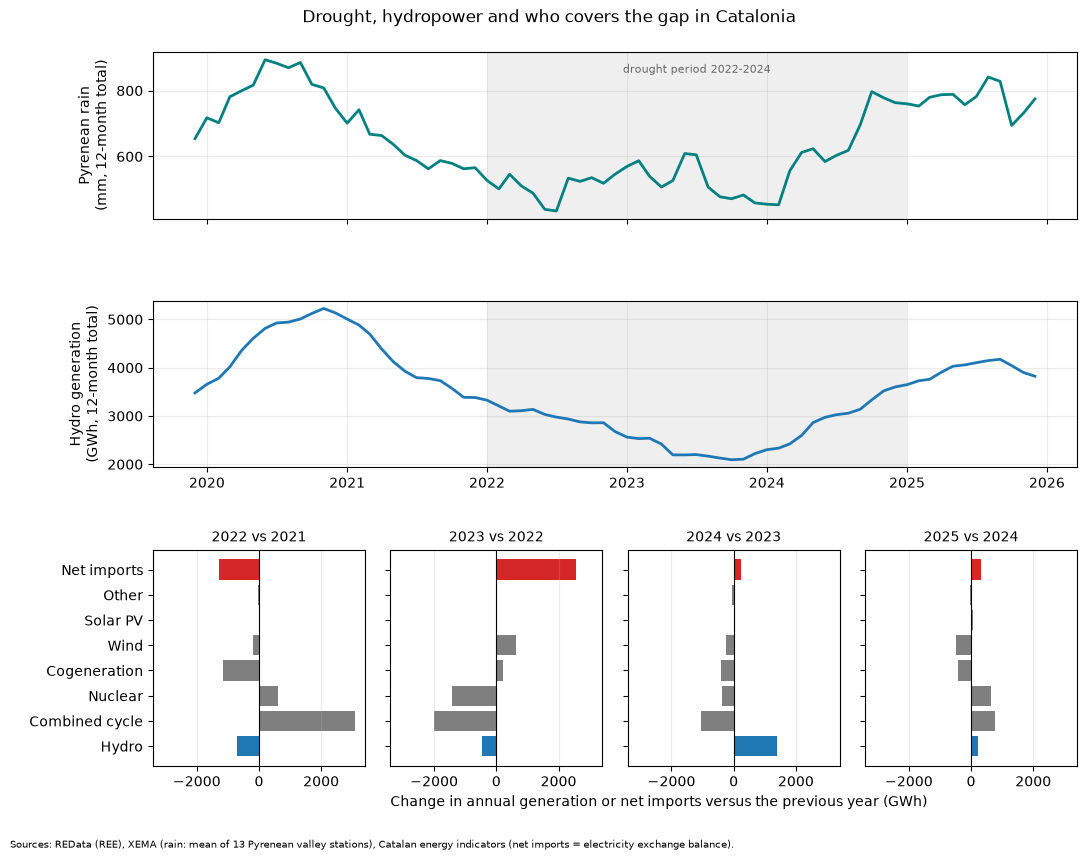

In [18]:
fig = plt.figure(figsize=(11, 8.6))
gs = fig.add_gridspec(3, 4, height_ratios=[1, 1, 1.3], hspace=0.45, wspace=0.12)
ax_r = fig.add_subplot(gs[0, :])
ax_h = fig.add_subplot(gs[1, :], sharex=ax_r)
drought = (pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"))

rain12 = rain_m.rolling(12).sum()
hydro12 = hydro.rolling(12).sum()
ax_r.plot(rain12.index, rain12, color="teal", lw=2)
ax_r.set_ylabel("Pyrenean rain\n(mm, 12-month total)")
ax_h.plot(hydro12.index, hydro12, color="tab:blue", lw=2)
ax_h.set_ylabel("Hydro generation\n(GWh, 12-month total)")
for ax in (ax_r, ax_h):
    ax.axvspan(*drought, color="grey", alpha=0.12, lw=0)
    ax.grid(alpha=0.25)
plt.setp(ax_r.get_xticklabels(), visible=False)
ax_r.text(drought[0] + (drought[1] - drought[0]) / 2, 0.93, "drought period 2022-2024",
          transform=ax_r.get_xaxis_transform(), ha="center", va="top", fontsize=8,
          color="dimgrey")

names = list(change.columns)
colors = ["tab:blue" if n == "Hydro" else "tab:red" if n == "Net imports" else "tab:grey"
          for n in names]
lim = 1.1 * change.abs().to_numpy().max()
bar_axes = []
for j, year in enumerate(change.index):
    ax = fig.add_subplot(gs[2, j], sharex=bar_axes[0] if bar_axes else None,
                         sharey=bar_axes[0] if bar_axes else None)
    ax.barh(names, change.loc[year], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{year} vs {year - 1}", fontsize=10)
    ax.set_xlim(-lim, lim)
    ax.invert_yaxis()
    ax.grid(alpha=0.25, axis="x")
    if j > 0:
        plt.setp(ax.get_yticklabels(), visible=False)
    bar_axes.append(ax)
bar_axes[1].set_xlabel("Change in annual generation or net imports versus the previous "
                       "year (GWh)", loc="left")

fig.suptitle("Drought, hydropower and who covers the gap in Catalonia")
fig.text(0.01, 0.005,
         "Sources: REData (REE), XEMA (rain: mean of 13 Pyrenean valley stations), Catalan "
         "energy indicators (net imports = electricity exchange balance).",
         fontsize=7, ha="left")
fig.subplots_adjust(left=0.14, right=0.98, top=0.93, bottom=0.1)

out = Path("..") / "figures" / "Gabri"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "idea6_hydro_drought_replacement.png", dpi=200)
fig.savefig(out / "idea6_hydro_drought_replacement.svg")
